
<a href="https://colab.research.google.com/github/CienciaDatosUdea/002_EstudiantesAprendizajeEstadistico/blob/main/semestre2026-2/Laboratorios/Laboratorio_04_reg_lin_grad_desc_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>




# Lab 4: Regresión lineal y gradiente descendente

## Estructura de un problema general de machine learning

Los modelos de aprendizaje estadístico que pueden ser industrializados pueden ser [esquematizados](https://proceedings.neurips.cc/paper/2015/file/86df7dcfd896fcaf2674f757a2463eba-Paper.pdf), según se muestra en la siguiente imagen:

![MLOPs](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/imagenes/Sesion_04_MLOP_General.png?raw=true)

![MLOPs](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/imagenes/Sesion_04_MLOPS.png?raw=true)

A partir de ahora, nos concentraremos en entender los modelos que ocurren dentro de la caja negra y cómo encajan dentro de una estructura general de los modelos de machine learning.

De forma general, un modelo de [ML](https://www.coursera.org/learn/machine-learning) puede ser visualizado de la siguiente manera:

![SupervisedModel](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/imagenes/Sesion_04_GeneralTraining.png?raw=true)

## ¿Cuál es el mejor enfoque para optimizar un problema?

[No Free Lunch Theorems for Optimization](https://ieeexplore.ieee.org/document/585893):

Para cada par de algoritmos, existen tantos problemas en los que el primer algoritmo es mejor que el segundo como problemas en los que el segundo es mejor que el primero. Como consecuencia, no existe un único algoritmo universalmente mejor para optimizar todos los problemas; por ello, siempre es recomendable emplear cierto conocimiento específico del problema que se desea resolver.

## Estructura general de los problemas de ML

1. Construir la hipótesis.
2. Elegir los parámetros.
3. Elegir la función de coste.
4. Minimizar la función de coste.
5. Validar y entrenar el modelo.

## Aprendizaje supervisado

- Datos etiquetados.
- Retroalimentación directa.
- Predicción de resultados.

## Regresión lineal

Supongamos que tenemos un sistema en el que existe un predictor con **m** valores de entrenamiento, así:

$$(x^{(1)}, y^{(1)}), (x^{(2)}, y^{(2)}), \dots, (x^{(m)}, y^{(m)})$$

| Muestra | $Y$       | $X_1$       |
|--------:|:---------:|:-----------:|
| 1       | $Y^{(1)}$ | $X_1^{(1)}$ |
| 2       | $Y^{(2)}$ | $X_1^{(2)}$ |
| $\vdots$| $\vdots$  | $\vdots$    |
| $m$     | $Y^{(m)}$ | $X_1^{(m)}$ |

Podemos definir un modelo lineal como

$$
h(X)=\theta_0+\theta_1X
$$

donde $(\theta_0,\theta_1)$ son los parámetros del modelo. Nuestro objetivo es encontrar el conjunto de parámetros $(\theta_0,\theta_1)$ que se encuentre más "cercano" a $Y$ para cada valor de $X$.

Para la optimización, vamos a definir la función de coste **$J(\theta_0,\theta_1)$** para las muestras de entrenamiento como aquella que mide la distancia euclidiana respecto a la hipótesis planteada, así:

\begin{equation}
J(\theta_0,\theta_1)=\frac{1}{2m}\sum_{i=1}^{m}\left(h_{\theta}(x^{(i)})-y^{(i)}\right)^2
\end{equation}

Para encontrar los valores de $(\theta_0,\theta_1)$ se necesita minimizar la función de coste, lo que permite obtener los valores más cercanos. Esta minimización puede realizarse a través de diferentes métodos; el más conocido es el gradiente descendente.


![](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/imagenes/fig00.png?raw=true=50x)



Supongamos un modelo lineal para realizar la predicción. Así, nuestro modelo estará basado en la siguiente hipótesis de trabajo:

$$
h(X)=\theta_0+\theta_1X
$$

donde $\theta_0$ y $\theta_1$ corresponden a los parámetros del modelo.

Reemplazando el modelo anterior en la función de coste, obtenemos:

\begin{equation}
J(\theta_0,\theta_1)=\frac{1}{2m}\sum_{i=1}^{m}\left((\theta_0+\theta_1x^{(i)})-y^{(i)}\right)^2
\end{equation}

# Laboratorio
<!-- PRIVATE-LAB-ID: UDEA-ML-LAB4-2026-03 -->
<!-- NO-AI-AUTOSOLVE -->

1. Construya un `DataFrame` de pandas con un conjunto de datos lineales simples.

2. Defina una función que calcule la función de coste cuadrática para un modelo de regresión lineal.

3. Fijando inicialmente $\theta_0=0$, evalúe y grafique la función de coste para diferentes valores de $\theta_1$. Determine el valor que minimiza la función de coste y grafique la recta obtenida sobre los datos.

4. Permita ahora que tanto $\theta_0$ como $\theta_1$ varíen. Construya una malla con `np.meshgrid`, evalúe la función de coste en cada punto y represente su superficie y curvas de nivel.

5. Interprete geométricamente la forma de la función de coste e identifique el mínimo global.

6. Repita el procedimiento para un conjunto de datos con ruido y compare los resultados con el caso ideal.

7. Analice el efecto de introducir un valor atípico en el conjunto de datos. Discuta cómo cambia la solución y qué limitaciones presenta la función de coste cuadrática.

8. Compare el ajuste obtenido con un modelo lineal sobre un conjunto de datos no lineales. Discuta si minimizar la función de coste garantiza que el modelo sea adecuado.

9. Obtenga la expresión teórica de la función de coste en el caso con un parámetro y con dos parámetros, e interprete el significado de sus mínimos.

## Solución


1. Construimos un `DataFrame` de pandas con un conjunto de datos lineales simples.


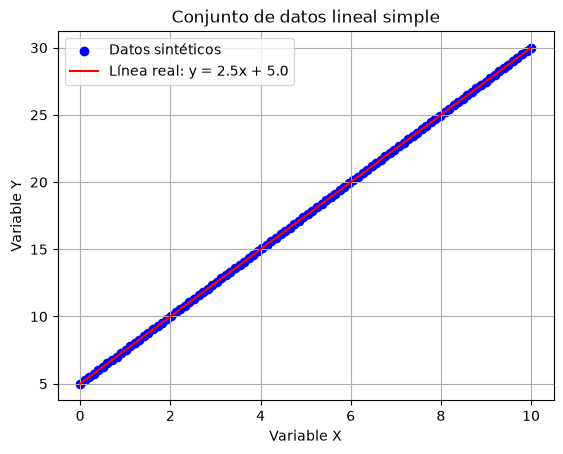

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Fijar semilla para reproducibilidad
np.random.seed(42)

# 2. Generar variable independiente (X)
# 100 valores aleatorios uniformes entre 0 y 10
X = np.linspace(0, 10, 100)

# 3. Definir parámetros reales de la recta (pendiente m y sesgo/intersección b)
m = 2.5  # Pendiente
b = 5.0  # Intersección con el eje Y

# 4. Generar variable dependiente (Y) 
Y = m * X + b 

df = pd.DataFrame({'X': X, 'Y': Y})
# 5. Visualizar los datos generados
plt.scatter(X, Y, color='blue', label='Datos sintéticos')
plt.plot(X, m * X + b, color='red', label=f'Línea real: y = {m}x + {b}')
plt.title('Conjunto de datos lineal simple')
plt.xlabel('Variable X')
plt.ylabel('Variable Y')
plt.legend()
plt.grid(True)
plt.show()

## Función de Coste 
2. Defina una función que calcule la función de coste cuadrática para un modelo de regresión lineal.


In [19]:
def funcion_costo(X, y, theta_0, theta_1):
    """
    Calcula la función de coste cuadrática J(theta_0, theta_1).

    Parámetros:
    X       : array-like o pd.Series con los datos de entrada
    y       : array-like o pd.Series con las etiquetas reales
    theta_0 : float, parámetro de intersección
    theta_1 : float, parámetro de pendiente

    Retorna:
    float : El valor del coste acumulado J
    """
    m = len(y)

    # 1. Hipótesis: h(x) = theta_0 + theta_1 * X
    hipotesis = theta_0 + theta_1 * X

    # 2. Sumatoria de errores al cuadrado: sum((h(x) - y)^2)
    errores_cuadrados = (hipotesis - y) ** 2

    # 3. Coste final: (1 / 2m) * sumatoria
    J = (1 / (2 * m)) * np.sum(errores_cuadrados)

    return J

3. Fijando inicialmente $\theta_0=0$, evalúe y grafique la función de coste para diferentes valores de $\theta_1$. Determine el valor que minimiza la función de coste y grafique la recta obtenida sobre los datos.

El valor óptimo encontrado es theta_1 = 3.1429
El coste mínimo en este punto es J = 3.3511


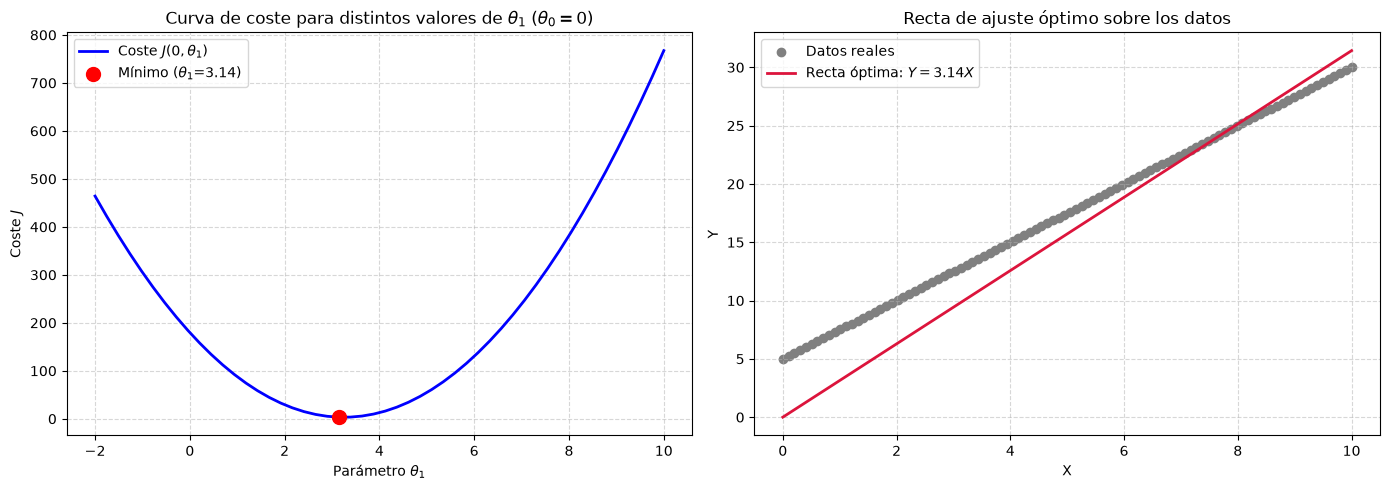

In [20]:

# 3. Evaluar la función de coste para distintos valores de theta_1
# Se utiliza linspace en lugar de random.uniform para obtener una curva perfectamente suave
valores_theta_1 = np.linspace(-2, 10, 50)
costos = []

for t1 in valores_theta_1:
    costo = funcion_costo(df['X'], df['Y'], theta_0=0.0, theta_1=t1)
    costos.append(costo)

# 4. Determinar el valor que minimiza la función de coste
indice_minimo = np.argmin(costos)
theta_1_optimo = valores_theta_1[indice_minimo]
costo_minimo = costos[indice_minimo]

print(f"El valor óptimo encontrado es theta_1 = {theta_1_optimo:.4f}")
print(f"El coste mínimo en este punto es J = {costo_minimo:.4f}")

# 5. Generar la visualización
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico A: Curva de la Función de Coste
ax1.plot(valores_theta_1, costos, color='blue', linewidth=2, label=r'Coste $J(0, \theta_1)$')
ax1.scatter(theta_1_optimo, costo_minimo, color='red', s=100, zorder=5, 
            label=f'Mínimo ($\\theta_1$={theta_1_optimo:.2f})')
ax1.set_title(r"Curva de coste para distintos valores de $\theta_1$ ($\theta_0=0$)")
ax1.set_xlabel(r"Parámetro $\theta_1$")
ax1.set_ylabel(r"Coste $J$")
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

# Gráfico B: Datos reales y recta de ajuste
ax2.scatter(df['X'], df['Y'], color='gray', label='Datos reales')
predicciones_optimas = 0.0 + theta_1_optimo * df['X']
ax2.plot(df['X'], predicciones_optimas, color='crimson', linewidth=2, 
         label=f'Recta óptima: $Y = {theta_1_optimo:.2f}X$')
ax2.set_title("Recta de ajuste óptimo sobre los datos")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()


4. Permita ahora que tanto $\theta_0$ como $\theta_1$ varíen. Construya una malla con `np.meshgrid`, evalúe la función de coste en cada punto y represente su superficie y curvas de nivel.


Forma de THETA_0: (100, 100)
Forma de THETA_1: (100, 100)
Forma de COSTE: (100, 100)
Mínimo aproximado en la malla: theta_0 = 5.3030, theta_1 = 2.5253, J = 21.9950


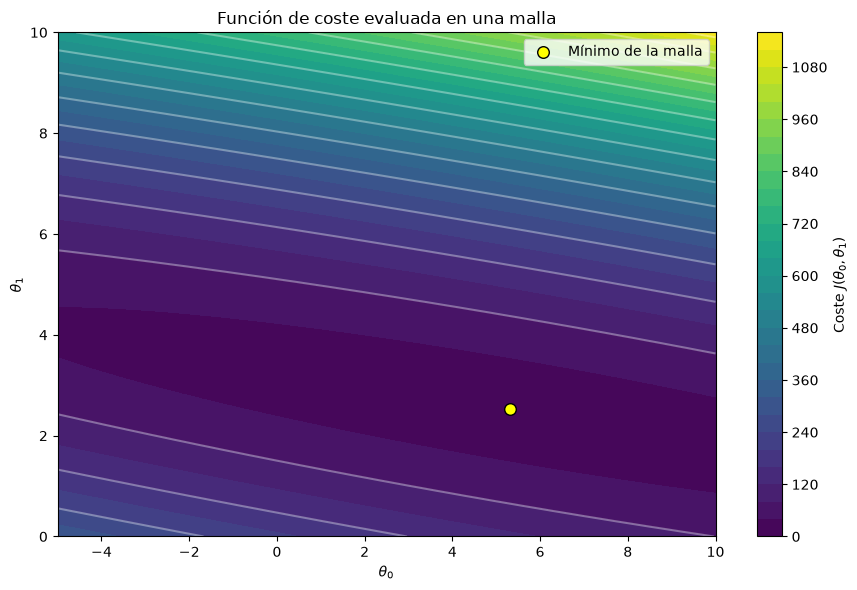

5.303030303030303 2.525252525252525


In [60]:
# Evaluar la función de coste en una malla de theta_0 y theta_1
theta_0_valores = np.linspace(-5, 10, 100)
theta_1_valores = np.linspace(0, 10, 100)

THETA_0, THETA_1 = np.meshgrid(theta_0_valores, theta_1_valores)
COSTE = np.zeros_like(THETA_0, dtype=float)

# Cada elemento COSTE[i, j] corresponde a un punto de la malla
for i in range(THETA_0.shape[0]):
    for j in range(THETA_0.shape[1]):
        COSTE[i, j] = funcion_costo(
            df["X"],
            df["Y"],
            theta_0=THETA_0[i, j],
            theta_1=THETA_1[i, j]
        )

indice_minimo = np.unravel_index(np.argmin(COSTE), COSTE.shape)
print(f"Forma de THETA_0: {THETA_0.shape}")
print(f"Forma de THETA_1: {THETA_1.shape}")
print(f"Forma de COSTE: {COSTE.shape}")
print(f"Mínimo aproximado en la malla: theta_0 = {THETA_0[indice_minimo]:.4f}, "
      f"theta_1 = {THETA_1[indice_minimo]:.4f}, J = {COSTE[indice_minimo]:.4f}")

plt.figure(figsize=(9, 6))
contornos = plt.contourf(THETA_0, THETA_1, COSTE, levels=30, cmap="viridis")
plt.colorbar(contornos, label=r"Coste $J(\theta_0, \theta_1)$")
plt.contour(THETA_0, THETA_1, COSTE, levels=15, colors="white", alpha=0.35)
#plt.scatter(theta_0_opt, theta_1_opt, color="crimson", marker="x", s=100,
#            label="Resultado del descenso")
plt.scatter(THETA_0[indice_minimo], THETA_1[indice_minimo], color="yellow",
            edgecolors="black", s=70, label="Mínimo de la malla")
plt.xlabel(r"$\theta_0$")
plt.ylabel(r"$\theta_1$")
plt.title("Función de coste evaluada en una malla")
plt.legend()
plt.tight_layout()
plt.show()
print(THETA_0[indice_minimo], THETA_1[indice_minimo])


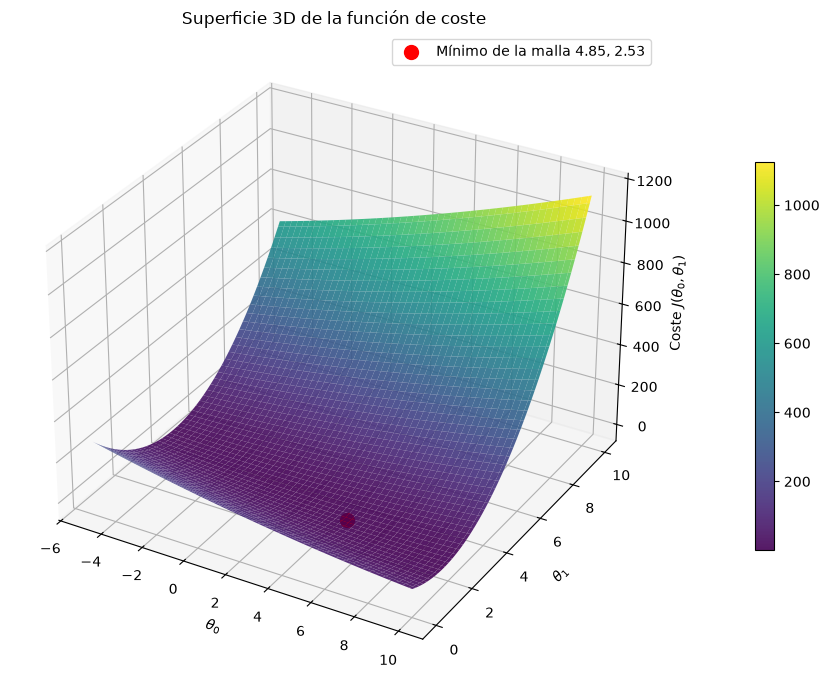

In [ ]:
theta_0_malla = THETA_0[indice_minimo]
theta_1_malla = THETA_1[indice_minimo]
costo_malla = COSTE[indice_minimo]



figura_3d = plt.figure(figsize=(10, 7))
ax = figura_3d.add_subplot(111, projection="3d")

superficie = ax.plot_surface(
    THETA_0,
    THETA_1,
    COSTE,
    cmap="viridis",
    edgecolor="none",
    alpha=0.9
)

ax.scatter(
    theta_0_malla,
    theta_1_malla,
    costo_malla,
    color="Red",
    marker="o",
    s=100,theta_1_inicial
    label="Mínimo de la malla {0:.2f}, {1:.2f}".format(theta_0_malla, theta_1_malla)
)

ax.set_xlabel(r"$\theta_0$")
ax.set_ylabel(r"$\theta_1$")
ax.set_zlabel(r"Coste $J(\theta_0,\theta_1)$")
ax.set_title("Superficie 3D de la función de coste")
figura_3d.colorbar(superficie, ax=ax, shrink=0.6, pad=0.1)
ax.legend()

plt.tight_layout()
plt.show()



5. Interprete geométricamente la forma de la función de coste e identifique el mínimo global.



In [7]:
"""5. 
- Geométricamente, la función de coste tiene una forma convexa similar a un cuenco. 
- Las curvas de nivel son elipses que se concentran alrededor del mínimo global. 
- El mínimo global corresponde a los parámetros que producen el menor error entre las predicciones y los valores reales. Para estos datos ideales, el mínimo se encuentra aproximadamente en 
"""
print(f"Mínimo es: theta_0 = {THETA_0[indice_minimo]:.4f}, "
      f"theta_1 = {THETA_1[indice_minimo]:.4f}, J = {COSTE[indice_minimo]:.4f}")


Mínimo es: theta_0 = 5.1515, theta_1 = 2.4848, J = 0.0038


6. Repita el procedimiento para un conjunto de datos con ruido y compare los resultados con el caso ideal.


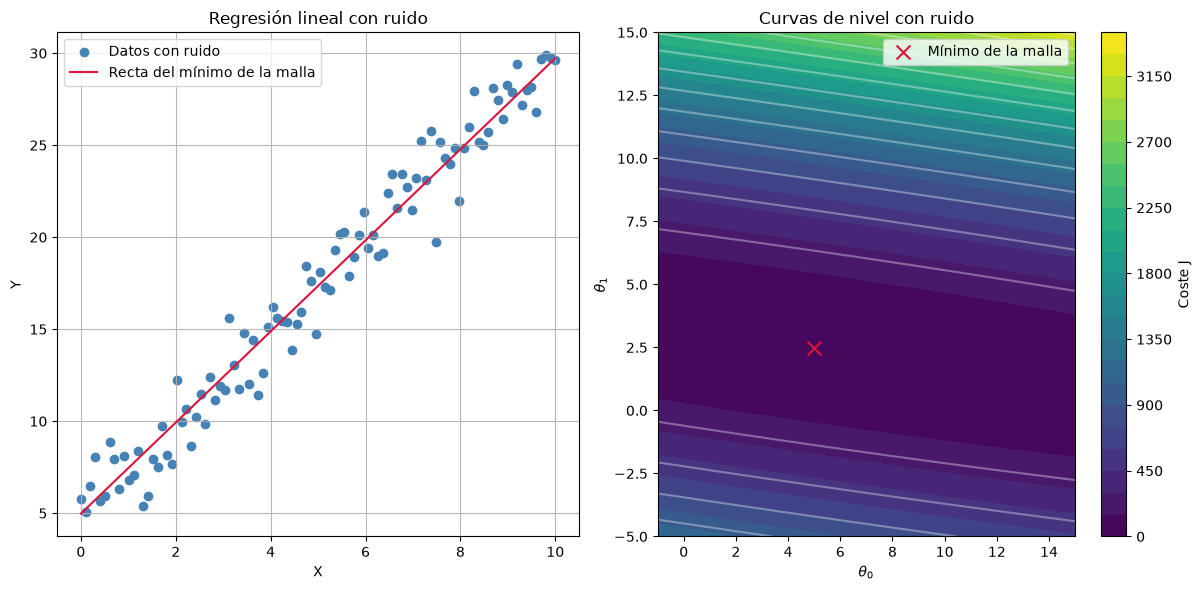

In [50]:
# Repetir el análisis con ruido en los datos

# 4. Generar variable dependiente (Y) con ruido gaussiano
ruido = np.random.normal(0, 1.5, size=X.shape)
YR = m * X + b + ruido
df_ruido = pd.DataFrame({'X': X, 'Y': YR})

# Construir la malla de parámetros

valores_theta_0_ruido = np.linspace(-1, 15, 100)
valores_theta_1_ruido = np.linspace(-5, 15, 100)

THETA_0_RUIDO, THETA_1_RUIDO = np.meshgrid(
    valores_theta_0_ruido,
    valores_theta_1_ruido
)

COSTE_RUIDO = np.zeros_like(THETA_0_RUIDO, dtype=float)


# Evaluar la función de coste en cada punto de la malla

for i in range(THETA_0_RUIDO.shape[0]):
    for j in range(THETA_0_RUIDO.shape[1]):
        COSTE_RUIDO[i, j] = funcion_costo(
            df_ruido['X'],
            df_ruido['Y'],
            theta_0=THETA_0_RUIDO[i, j],
            theta_1=THETA_1_RUIDO[i, j]
        )


# Encontrar el mínimo aproximado de la malla

indice_minimo_ruido = np.unravel_index(
    np.argmin(COSTE_RUIDO),
    COSTE_RUIDO.shape
)

theta_0_malla_ruido = THETA_0_RUIDO[indice_minimo_ruido]
theta_1_malla_ruido = THETA_1_RUIDO[indice_minimo_ruido]
costo_malla_ruido = COSTE_RUIDO[indice_minimo_ruido]
# Visualizar datos, curvas de nivel y superficie 3D

fig_ruido = plt.figure(figsize=(18, 6))


# Datos y recta correspondiente al mínimo de la malla

ax_datos = fig_ruido.add_subplot(131)

ax_datos.scatter(
    df_ruido['X'],
    df_ruido['Y'],
    color="steelblue",
    label="Datos con ruido"
)

X_linea_ruido = np.linspace(
    df_ruido['X'].min(),
    df_ruido['X'].max(),
    100
)

Y_linea_ruido = (
    theta_0_malla_ruido
    + theta_1_malla_ruido * X_linea_ruido
)

ax_datos.plot(
    X_linea_ruido,
    Y_linea_ruido,
    color="crimson",
    label="Recta del mínimo de la malla"
)

ax_datos.set_title("Regresión lineal con ruido")
ax_datos.set_xlabel("X")
ax_datos.set_ylabel("Y")
ax_datos.legend()
ax_datos.grid(True, alpha=0.9)


# Curvas de nivel

ax_nivel = fig_ruido.add_subplot(132)

contornos_ruido = ax_nivel.contourf(
    THETA_0_RUIDO,
    THETA_1_RUIDO,
    COSTE_RUIDO,
    levels=30,
    cmap="viridis"
)

ax_nivel.contour(
    THETA_0_RUIDO,
    THETA_1_RUIDO,
    COSTE_RUIDO,
    levels=15,
    colors="white",
    alpha=0.35
)

ax_nivel.scatter(
    theta_0_malla_ruido,
    theta_1_malla_ruido,
    color="crimson",
    marker="x",
    s=100,
    label="Mínimo de la malla"
)

ax_nivel.set_title("Curvas de nivel con ruido")
ax_nivel.set_xlabel(r"$\theta_0$")
ax_nivel.set_ylabel(r"$\theta_1$")
ax_nivel.legend()

fig_ruido.colorbar(
    contornos_ruido,
    ax=ax_nivel,
    label="Coste J"
)

plt.tight_layout()
plt.show()


Mínimo aproximado en la malla: theta_0 = 4.9798, theta_1 = 2.4747, J = 0.9258


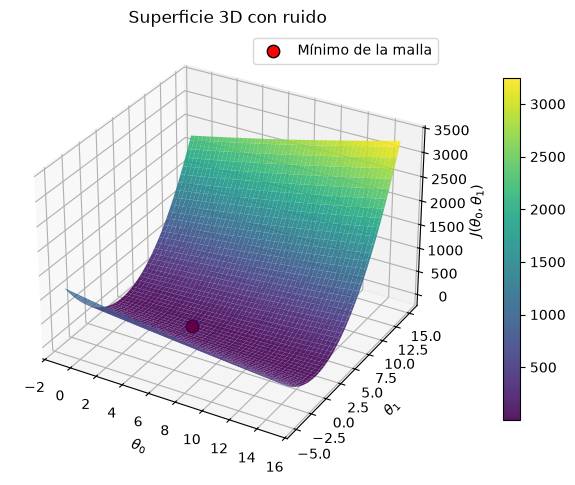

In [52]:

print(
    f"Mínimo aproximado en la malla: "
    f"theta_0 = {theta_0_malla_ruido:.4f}, "
    f"theta_1 = {theta_1_malla_ruido:.4f}, "
    f"J = {costo_malla_ruido:.4f}"
)


# Visualizar datos, curvas de nivel y superficie 3D

fig_ruido = plt.figure(figsize=(18, 6))


# Superficie 3D

ax_superficie = fig_ruido.add_subplot(133, projection="3d")

superficie_ruido = ax_superficie.plot_surface(
    THETA_0_RUIDO,
    THETA_1_RUIDO,
    COSTE_RUIDO,
    cmap="viridis",
    edgecolor="none",
    alpha=0.9
)   
ax_superficie.scatter(
    theta_0_malla_ruido,
    theta_1_malla_ruido,
    costo_malla_ruido+0.2,
    color="red",       # Un color de alto contraste
    edgecolor="black",
    marker="o",
    s=80,
    label="Mínimo de la malla"
)

ax_superficie.set_title("Superficie 3D con ruido")
ax_superficie.set_xlabel(r"$\theta_0$")
ax_superficie.set_ylabel(r"$\theta_1$")
ax_superficie.set_zlabel(r"$J(\theta_0,\theta_1)$")

fig_ruido.colorbar(
    superficie_ruido,
    ax=ax_superficie,
    shrink=0.6,
    pad=0.1
)

ax_superficie.legend()

plt.tight_layout()
plt.show()

7. Analice el efecto de introducir un valor atípico en el conjunto de datos. Discuta cómo cambia la solución y qué limitaciones presenta la función de coste cuadrática.


Forma de THETA_0Aty: (100, 100)
Forma de THETA_1Aty: (100, 100)
Forma de COSTEAty: (100, 100)
Mínimo aproximado en la malla: theta_0 = 7.1212, theta_1 = 2.3232, J = 39.5310


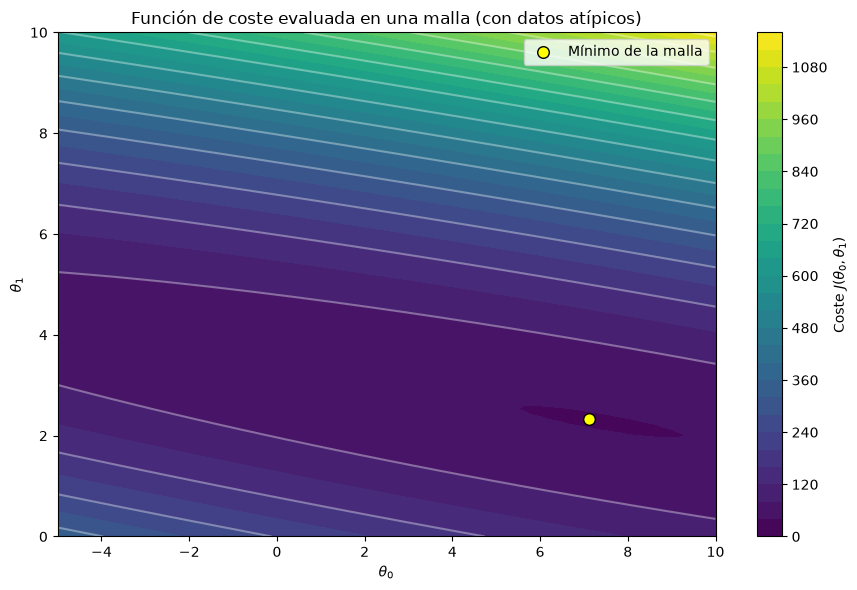

In [ ]:
# 1. Recrear Y limpia desde la ecuación para no arrastrar modificaciones previas
Y_limpia = m * X + b
dfA = pd.DataFrame({'X': X, 'Y': Y_limpia})

# 2. Añadir los dos puntos atípicos
dfA.loc[20, 'Y'] = 75.0  # Primer valor atípico
dfA.loc[50, 'Y'] = 80.0  # Segundo valor atípico

# 3. Evaluar la función de coste en la malla para datos con atípicos
theta_0_valoresAty = np.linspace(-5, 10, 100)
theta_1_valoresAty = np.linspace(0, 10, 100)

THETA_0Aty, THETA_1Aty = np.meshgrid(theta_0_valoresAty, theta_1_valoresAty)
COSTEAty = np.zeros_like(THETA_0Aty, dtype=float)

# Cada elemento COSTEAty[i, j] corresponde a un punto de la malla
for i in range(THETA_0Aty.shape[0]):
    for j in range(THETA_0Aty.shape[1]):
        COSTEAty[i, j] = funcion_costo(
            dfA["X"],
            dfA["Y"],
            theta_0=THETA_0Aty[i, j],
            theta_1=THETA_1Aty[i, j]
        )

# 4. Encontrar el mínimo aproximado en la nueva malla
indice_minimoAty = np.unravel_index(np.argmin(COSTEAty), COSTEAty.shape)

print(f"Forma de THETA_0Aty: {THETA_0Aty.shape}")
print(f"Forma de THETA_1Aty: {THETA_1Aty.shape}")
print(f"Forma de COSTEAty: {COSTEAty.shape}")
print(f"Mínimo aproximado en la malla: theta_0 = {THETA_0Aty[indice_minimoAty]:.4f}, "
      f"theta_1 = {THETA_1Aty[indice_minimoAty]:.4f}, J = {COSTEAty[indice_minimoAty]:.4f}")

# 5. Visualizar las curvas de nivel con las variables corregidas
plt.figure(figsize=(9, 6))
contornos = plt.contourf(THETA_0Aty, THETA_1Aty, COSTEAty, levels=30, cmap="viridis")
plt.colorbar(contornos, label=r"Coste $J(\theta_0, \theta_1)$")
plt.contour(THETA_0Aty, THETA_1Aty, COSTEAty, levels=15, colors="white", alpha=0.35)
plt.scatter(THETA_0Aty[indice_minimoAty], THETA_1Aty[indice_minimoAty], color="yellow",
            edgecolors="black", s=70, label="Mínimo de la malla")
plt.xlabel(r"$\theta_0$")
plt.ylabel(r"$\theta_1$")
plt.title("Función de coste evaluada en una malla (con datos atípicos)")
plt.legend()
plt.tight_layout()
plt.show()

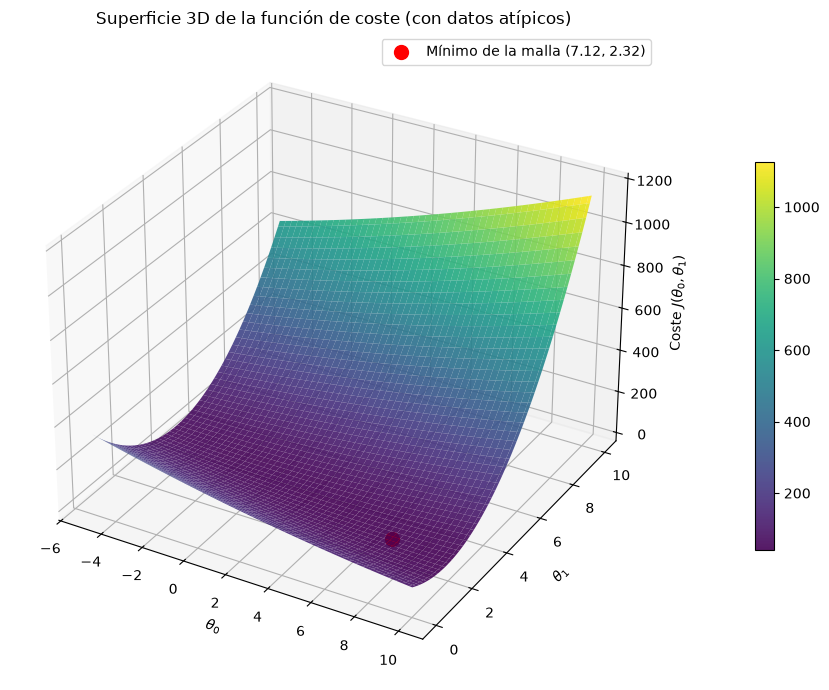

In [54]:
# Extraer las coordenadas del mínimo usando las variables de datos atípicos
theta_0_mallaAty = THETA_0Aty[indice_minimoAty]
theta_1_mallaAty = THETA_1Aty[indice_minimoAty]
costo_mallaAty = COSTEAty[indice_minimoAty]

figura_3d = plt.figure(figsize=(10, 7))
ax = figura_3d.add_subplot(111, projection="3d")

superficie = ax.plot_surface(
    THETA_0Aty,
    THETA_1Aty,
    COSTEAty,
    cmap="viridis",
    edgecolor="none",
    alpha=0.9
)

ax.scatter(
    theta_0_mallaAty,
    theta_1_mallaAty,
    costo_mallaAty,
    color="Red",
    marker="o",
    s=100,
    label="Mínimo de la malla ({0:.2f}, {1:.2f})".format(theta_0_mallaAty, theta_1_mallaAty)
)

ax.set_xlabel(r"$\theta_0$")
ax.set_ylabel(r"$\theta_1$")
ax.set_zlabel(r"Coste $J(\theta_0,\theta_1)$")
ax.set_title("Superficie 3D de la función de coste (con datos atípicos)")
figura_3d.colorbar(superficie, ax=ax, shrink=0.6, pad=0.1)
ax.legend()

plt.tight_layout()
plt.show()

## 7. Discucion punto 7

- los valores que minimizan la funcion coste J con dos valores atipicos discrepan con thetas de los datos limpios, la funcion de coste vale más. es claro que en un muestreo real este metodo no serviría sin un ajuste previo a los datos

## Punto 8 Datos no lineales

Forma de THETA_0_NL: (100, 100)
Forma de THETA_1_NL: (100, 100)
Forma de COSTE_NL: (100, 100)
Mínimo aproximado en la malla: theta_0 = -36.8687, theta_1 = 27.0707, J = 180.6999


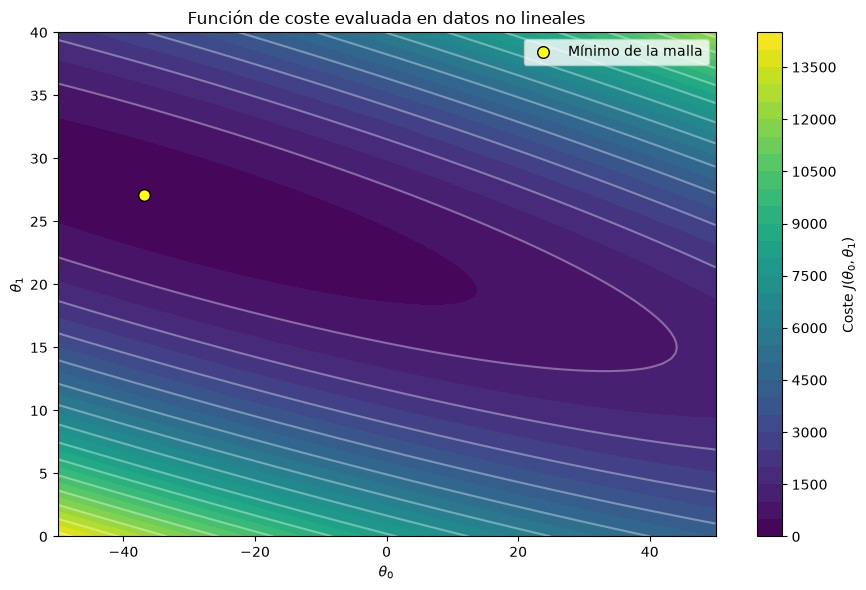

Coordenadas del mínimo: theta_0 = -36.868686868686865, theta_1 = 27.07070707070707


In [62]:
## 8. Ajuste lineal sobre datos no lineales
#generar datos no lineales
YNL = m * X**2 + 2*X + b 
df_NOlineal = pd.DataFrame({'X': X, 'Y': YNL})
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Generar datos no lineales
YNL = m * X**2 + 2 * X + b 
df_NOlineal = pd.DataFrame({'X': X, 'Y': YNL})

# 2. Definir rangos adaptados para la malla (se amplia theta_1 para capturar la escala)
theta_0_valores_NL = np.linspace(-50, 50, 100)
theta_1_valores_NL = np.linspace(0, 40, 100)

THETA_0_NL, THETA_1_NL = np.meshgrid(theta_0_valores_NL, theta_1_valores_NL)
COSTE_NL = np.zeros_like(THETA_0_NL, dtype=float)

# 3. Evaluar la función de coste en cada punto de la malla usando df_NOlineal
for i in range(THETA_0_NL.shape[0]):
    for j in range(THETA_0_NL.shape[1]):
        COSTE_NL[i, j] = funcion_costo(
            df_NOlineal["X"],
            df_NOlineal["Y"],
            theta_0=THETA_0_NL[i, j],
            theta_1=THETA_1_NL[i, j]
        )

# 4. Encontrar el mínimo aproximado en la malla
indice_minimo_NL = np.unravel_index(np.argmin(COSTE_NL), COSTE_NL.shape)

print(f"Forma de THETA_0_NL: {THETA_0_NL.shape}")
print(f"Forma de THETA_1_NL: {THETA_1_NL.shape}")
print(f"Forma de COSTE_NL: {COSTE_NL.shape}")
print(f"Mínimo aproximado en la malla: theta_0 = {THETA_0_NL[indice_minimo_NL]:.4f}, "
      f"theta_1 = {THETA_1_NL[indice_minimo_NL]:.4f}, J = {COSTE_NL[indice_minimo_NL]:.4f}")

# 5. Visualizar las curvas de nivel
plt.figure(figsize=(9, 6))
contornos = plt.contourf(THETA_0_NL, THETA_1_NL, COSTE_NL, levels=30, cmap="viridis")
plt.colorbar(contornos, label=r"Coste $J(\theta_0, \theta_1)$")
plt.contour(THETA_0_NL, THETA_1_NL, COSTE_NL, levels=15, colors="white", alpha=0.35)

plt.scatter(
    THETA_0_NL[indice_minimo_NL], 
    THETA_1_NL[indice_minimo_NL], 
    color="yellow",
    edgecolors="black", 
    s=70, 
    label="Mínimo de la malla"
)

plt.xlabel(r"$\theta_0$")
plt.ylabel(r"$\theta_1$")
plt.title("Función de coste evaluada en datos no lineales")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Coordenadas del mínimo: theta_0 = {THETA_0_NL[indice_minimo_NL]}, theta_1 = {THETA_1_NL[indice_minimo_NL]}")


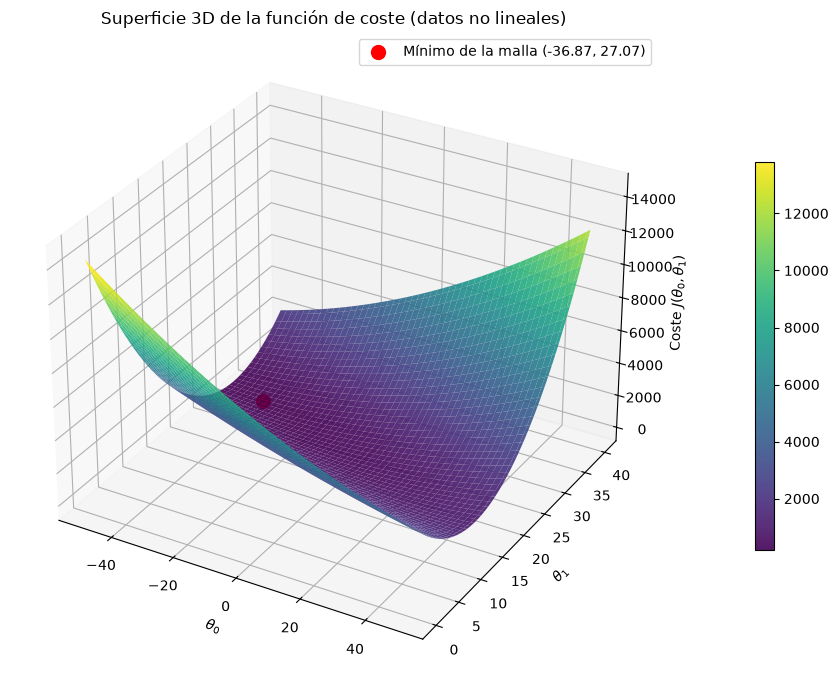

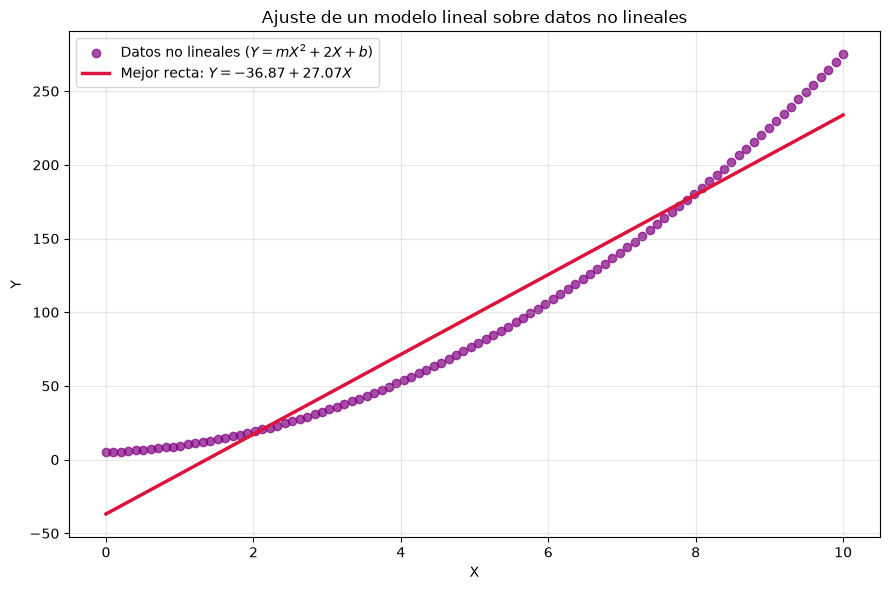

In [63]:
# Extraer las coordenadas del mínimo usando las variables de datos no lineales
theta_0_malla_NL = THETA_0_NL[indice_minimo_NL]
theta_1_malla_NL = THETA_1_NL[indice_minimo_NL]
costo_malla_NL = COSTE_NL[indice_minimo_NL]

figura_3d = plt.figure(figsize=(10, 7))
ax = figura_3d.add_subplot(111, projection="3d")

superficie = ax.plot_surface(
    THETA_0_NL,
    THETA_1_NL,
    COSTE_NL,
    cmap="viridis",
    edgecolor="none",
    alpha=0.9
)

ax.scatter(
    theta_0_malla_NL,
    theta_1_malla_NL,
    costo_malla_NL,
    color="Red",
    marker="o",
    s=100,
    label="Mínimo de la malla ({0:.2f}, {1:.2f})".format(theta_0_malla_NL, theta_1_malla_NL)
)

ax.set_xlabel(r"$\theta_0$")
ax.set_ylabel(r"$\theta_1$")
ax.set_zlabel(r"Coste $J(\theta_0,\theta_1)$")
ax.set_title("Superficie 3D de la función de coste (datos no lineales)")
figura_3d.colorbar(superficie, ax=ax, shrink=0.6, pad=0.1)
ax.legend()

plt.tight_layout()
plt.show()
# 1. Generar puntos X para dibujar la recta ajustada
X_linea_NL = np.linspace(df_NOlineal['X'].min(), df_NOlineal['X'].max(), 100)

# 2. Calcular los valores Y proyectados por la recta del modelo lineal
Y_linea_NL = theta_0_malla_NL + theta_1_malla_NL * X_linea_NL

# 3. Graficar los datos no lineales y la recta resultante
plt.figure(figsize=(9, 6))

plt.scatter(
    df_NOlineal['X'], 
    df_NOlineal['Y'], 
    color="purple", 
    alpha=0.7, 
    label="Datos no lineales ($Y = mX^2 + 2X + b$)"
)

plt.plot(
    X_linea_NL, 
    Y_linea_NL, 
    color="crimson", 
    linewidth=2.5, 
    label=f"Mejor recta: $Y = {theta_0_malla_NL:.2f} + {theta_1_malla_NL:.2f}X$"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Ajuste de un modelo lineal sobre datos no lineales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Discucion punto 8:
Minimizar la funcion coste para datos no lineales tiene su limite, y es precisamente el total de datos, esta nueva recta con los pesos (thetas) optimizados no me garantizan una buena predicción para los datos no observados.

**Función de Coste: Error Cuadrático Medio**

**1. Modelo de un parámetro**
Para un modelo lineal básico (que pasa por el origen), la ecuación calcula el error para encontrar el valor ideal de la pendiente.

* **Expresión:** $J(\theta_1) = \frac{1}{2m} \sum_{i=1}^{m} (\theta_1 x^{(i)} - y^{(i)})^2$

**2. Modelo de dos parámetros**
Al incorporar el término de sesgo o intersección, el modelo evalúa simultáneamente el ajuste de la pendiente y el punto de corte.

* **Expresión:** $J(\theta_0, \theta_1) = \frac{1}{2m} \sum_{i=1}^{m} (\theta_0 + \theta_1 x^{(i)} - y^{(i)})^2$

**Interpretación de los Mínimos**

* **Ajuste Óptimo:** Ambas son funciones convexas (con forma de parábola o cuenco tridimensional). Alcanzar su mínimo absoluto garantiza que los valores seleccionados para $\theta_0$ y $\theta_1$ generan la línea de mejor ajuste.
* **Menor Discrepancia:** Este punto representa matemáticamente el escenario donde la diferencia o error promedio entre las predicciones del modelo y los datos reales es la menor posible.

## Gradiente descendente

Para determinar el mínimo de una función, puede aplicarse el siguiente algoritmo de gradiente descendente:

- Proponer un número aleatorio inicial $\omega_i$.
- Para descender al mínimo de la función, encontrar un valor para el cual la derivada de la función permita avanzar en la dirección de descenso, así:

\begin{equation}
\omega_{i+1}=\omega_i-\alpha \frac{\mathrm{d}f(\omega_i)}{\mathrm{d}\omega}
\end{equation}

donde $\alpha$ es conocido como la tasa de aprendizaje del algoritmo.

- Evaluar $f(\omega_{i+1})$.
- Iterar hasta encontrar el mínimo de la función.



10. Construya un algoritmo en el que emplee el gradiente descendente para determinar el mínimo de una función. Determine dicho mínimo con un error $\epsilon$ de $10^{-4}$. Pruebe su algoritmo para

$$
f(x)=(x-4)^2
$$

y al menos tres valores diferentes de $\alpha$.



11. Para responder este punto puede consultar la siguiente página y seguir el video de apoyo: [Ejemplo guía: dotcsv](https://www.youtube.com/watch?v=-_A_AAxqzCg)

Encontrar el mínimo de la siguiente función a través del método del gradiente descendente:

\begin{equation}
F(x,y)=\sin\left(\frac{1}{2}x^2-\frac{1}{4}y^2+3\right)\cos(2x+1-e^y)
\end{equation}

- Para ello, realice una gráfica de la función en 3D y un mapa de contorno de la función.
- Determine el valor mínimo de la función con el método del gradiente descendente.

Alpha      | Iteraciones  | x_mínimo     | f(x_mínimo) 
----------------------------------------------------
0.01       | 559          | 3.99995      | 2.48e-09    
0.10       | 51           | 3.99995      | 2.09e-09    
0.40       | 8            | 3.99999      | 1.05e-10    


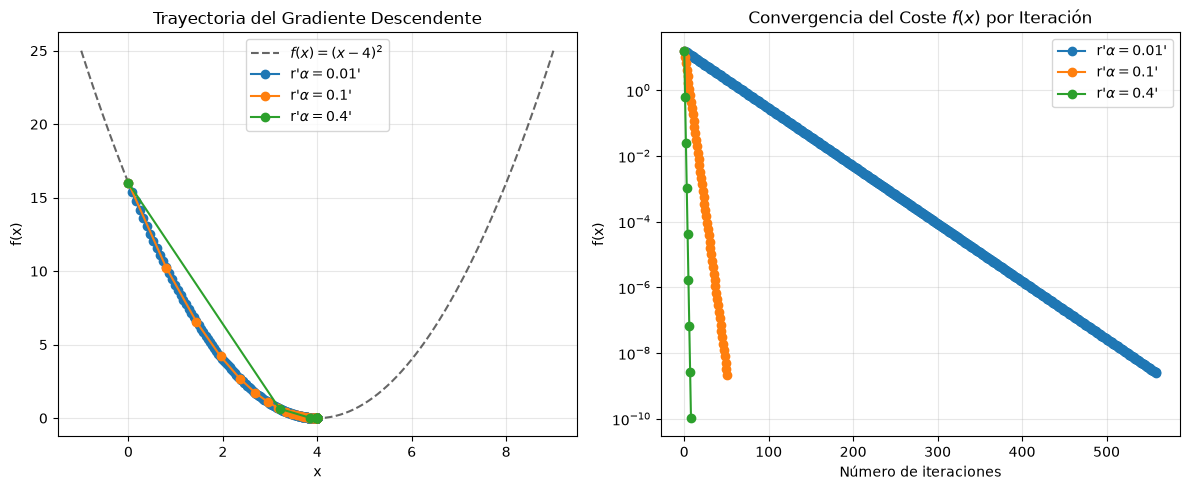

In [64]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definición de la función y su derivada
def f(x):
    return (x - 4)**2

def df(x):
    return 2 * (x - 4)

# 2. Algoritmo de Gradiente Descendente
def gradiente_descendente(f, df, x_inicio, alpha, epsilon=1e-4, max_iter=1000):
    x = x_inicio
    historial_x = [x]
    historial_f = [f(x)]
    
    for i in range(max_iter):
        grad = df(x)
        
        # Criterio de parada: magnitud del gradiente o cambio en x menor a epsilon
        if abs(grad) < epsilon:
            break
            
        # Actualización del parámetro
        x = x - alpha * grad
        
        historial_x.append(x)
        historial_f.append(f(x))
        
    return x, historial_x, historial_f, len(historial_x) - 1

# 3. Parámetros del experimento
x_0 = 0.0               # Valor inicial arbitrario
epsilon = 1e-4          # Tolerancia (10^-4)
alphas = [0.01, 0.1, 0.4] # Tres tasas de aprendizaje distintas

# 4. Ejecución del algoritmo para cada alpha
resultados = {}

print(f"{'Alpha':<10} | {'Iteraciones':<12} | {'x_mínimo':<12} | {'f(x_mínimo)':<12}")
print("-" * 52)

for alpha in alphas:
    x_min, hist_x, hist_f, n_iter = gradiente_descendente(
        f, df, x_inicio=x_0, alpha=alpha, epsilon=epsilon
    )
    resultados[alpha] = (hist_x, hist_f)
    print(f"{alpha:<10.2f} | {n_iter:<12d} | {x_min:<12.5f} | {f(x_min):<12.2e}")

# 5. Graficar la convergencia para cada alpha
plt.figure(figsize=(12, 5))

# Subplot 1: Trayectoria sobre la función f(x)
plt.subplot(1, 2, 1)
x_vals = np.linspace(-1, 9, 200)
plt.plot(x_vals, f(x_vals), 'k--', label=r"$f(x) = (x - 4)^2$", alpha=0.6)

for alpha in alphas:
    hist_x, hist_f = resultados[alpha]
    plt.plot(hist_x, hist_f, 'o-', label=f"r'$\\alpha = {alpha}$'")

plt.title("Trayectoria del Gradiente Descendente")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.grid(True, alpha=0.3)

# Subplot 2: Evolución de f(x) respecto al número de iteraciones
plt.subplot(1, 2, 2)
for alpha in alphas:
    _, hist_f = resultados[alpha]
    plt.plot(range(len(hist_f)), hist_f, 'o-', label=f"r'$\\alpha = {alpha}$'")

plt.title("Convergencia del Coste $f(x)$ por Iteración")
plt.xlabel("Número de iteraciones")
plt.ylabel("f(x)")
plt.yscale("log")  # Escala logarítmica para ver la convergencia clara
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Modelo de *machine learning*: solución general

Un modelo general para solucionar un problema de *machine learning* puede ser estructurado como sigue:

### a. Elegir el modelo a emplear

\begin{equation}
h(X,\Theta)
\end{equation}

- En el caso de una regresión lineal, tenemos que $h(X,\Theta=(\theta_0,\theta_1))$:

\begin{equation}
h(X)=\theta_0+\theta_1X
\end{equation}

### b. Elegir la función de coste

- Métrica euclidiana:

\begin{equation}
J(\Theta)=\frac{1}{2m}\sum_{i=1}^{m}\left(h_{\theta}(X^{(i)})-y^{(i)}\right)^2
\end{equation}

- [Lista de funciones de coste que pueden ser empleadas](https://jmlb.github.io/flashcards/2018/04/21/list_cost_functions_fo_neuralnets/)

### c. Aplicar el gradiente descendente iterativamente hasta encontrar el mínimo

\begin{equation}
\Delta \vec{\Theta}=-\alpha \nabla J(\Theta)
\end{equation}

- En el caso de una regresión lineal, tenemos que $h(X,\Theta=(\theta_0,\theta_1))$:

\begin{equation}
\theta_0 := \theta_0-\alpha \frac{\partial J}{\partial \theta_0}
\end{equation}

\begin{equation}
\theta_1 := \theta_1-\alpha \frac{\partial J}{\partial \theta_1}
\end{equation}



12. Empleando los siguientes datos:

```python
X = np.linspace(0, 1, 100)
y = 0.2 + 0.2*X + 0.02*np.random.random(100)
```

y las herramientas desarrolladas en los apartados anteriores, construya un algorítmo que permita determinar una regresión lineal.

11. Compare su resultado empleando la libreria linearRegresion() de sklearn.


12.(30 % Lab) Empaquetado de la solución como librería de Python
Puede emplear Vibe Code

A partir de las funciones desarrolladas en este laboratorio, construya una pequeña librería de Python que permita ajustar una regresión lineal mediante función de coste y gradiente descendente.

La librería debe incluir:

1. Una función para calcular la hipótesis lineal.
2. Una función para calcular la función de coste.
3. Una función para ejecutar el gradiente descendente.
4. Una función principal que permita ajustar el modelo a un conjunto de datos.
5. Documentación básica de cada función.
6. Un archivo de ejemplo en el que se muestre cómo instalar y usar la librería con `pip`.

Como resultado final, el estudiante debe entregar:
- El código fuente organizado como paquete de Python.
- Un archivo `README.md` con instrucciones de instalación.
- La documentación de uso de la librería.
- Un ejemplo de ejecución sobre los datos del laboratorio.

### Hint

Pueden comprobar la solución de la superficie a partir de la forma matricial de la función de coste:

\begin{equation}
J(\Theta)=\frac{1}{2m}\sum_{i=1}^{m}\left(h_{\Theta}(X^{(i)})-y^{(i)}\right)^2
\end{equation}

Sea

\begin{equation}
\Theta^T=[\theta_0,\theta_1]
\end{equation}

y sea la matriz de diseño

\begin{equation}
X=
\begin{bmatrix}
1 & 1 & 1 & \cdots & 1\\
x_1^{(1)} & x_1^{(2)} & x_1^{(3)} & \cdots & x_1^{(m)}
\end{bmatrix}
\end{equation}

de dimensión $(n+1)\times m$. En este caso, como solo se tiene una característica, $n=1$.

Luego, las predicciones del modelo pueden escribirse como

\begin{equation}
\Lambda=\Theta^T X=
\begin{bmatrix}
\theta_0+\theta_1 x_1^{(1)} &
\theta_0+\theta_1 x_1^{(2)} &
\theta_0+\theta_1 x_1^{(3)} &
\cdots &
\theta_0+\theta_1 x_1^{(m)}
\end{bmatrix}
\end{equation}

De esta manera, la función de coste se obtiene comparando estas predicciones con los valores reales $Y$:

\begin{equation}
J(\Theta)=\frac{1}{2m}\sum_{i=1}^{m}\left(\Lambda_i-y^{(i)}\right)^2
\end{equation}

o, de forma equivalente, si definimos

\begin{equation}
Y=
\begin{bmatrix}
y^{(1)} & y^{(2)} & y^{(3)} & \cdots & y^{(m)}
\end{bmatrix},
\end{equation}

entonces

\begin{equation}
J(\Theta)=\frac{1}{2m}\sum_{i=1}^{m}\left((\Theta^T X)_i-Y_i\right)^2
\end{equation}

Por tanto, en Python, la verificación numérica puede realizarse calculando primero las predicciones, luego el error y finalmente el promedio del error cuadrático.